# Input patches on the cortical sheet

This notebook trains Khona, Chandra et al.'s (2023) locality-masked RNN (LM-RNN), at **d = 10**, on the 82 Mod-Cog tasks, then changes **one thing**: where the inputs land on the sheet.

- **`baseline`** (Khona's setup): every input connects to all 2500 units.
- **`patched_wiring`**: each input group (fixation, ring 1, ring 2, rule) connects strictly to its own square patch of the sheet, dense inside the patch. The patches cover 53% of the sheet. The rest gets input only through local recurrence.

Everything else is identical: the same seed, data stream, recurrent mask, readout and optimizer. Training ran separately, on an RTX 4090 at about 6½ minutes per run:

`python -m cortical.train --condition {baseline,patched_wiring} --d 10 --seed 0 --out results/02_input_patches`

This notebook only loads the results. A pilot with smaller patches (23% of the sheet) at d = 6 scored 0.57 against 0.85 for dense wiring. That run is not kept here; see commit `ac521d4` in the git history.

## Setup

Khona et al. released no training code. Each setting below is marked as stated in the paper, inferred from the paper's parameter counts, or chosen by us.

| setting | value | source |
|---|---|---|
| tasks | Mod-Cog, 82 tasks, interleaved at random; one-hot rule input (115 inputs, 17 outputs) | paper |
| dynamics | `h_{t+1} = relu(W h_t + W_in u_t + b_ih + b_hh)`, `o = W_out h + b_out` | paper (equation); inferred (two biases); chosen (ReLU) |
| sheet | 50×50 = 2500 units on a torus | paper; inferred (periodic boundaries) |
| recurrent mask | torus distance ≤ 10, self-connections included: 792,500 weights (12.7%) | paper (d = 10 appears in its table); the counts match exactly |
| readout | dense | paper |
| init | PyTorch `nn.RNN` / `nn.Linear` defaults | inferred |
| training | Adam with lr 1e-3; unweighted cross-entropy at every step; batch 4 × 350 steps; 10k gradient steps | paper; batch and sequence length from the Mod-Cog README |
| seeds | 1 per condition | chosen (the paper used 15) |
| metric | a trial is correct only if the network holds fixation until the response period and outputs the target at every response step; 32 trials per task on a fixed evaluation set | chosen |

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from matplotlib.patches import Circle, Rectangle

from cortical.sheet import locality_mask
from cortical.wiring import INPUT_GROUPS, LAYOUT_B_LARGE, input_mask

RESULTS = Path("../results/02_input_patches")
CONDITIONS = ("baseline", "patched_wiring")
LAYOUT = LAYOUT_B_LARGE
L, D = 50, 10

SURFACE, INK, MUTED, RULE = "#fcfcfb", "#0b0b0b", "#52514e", "#c3c2b7"
CONDITION_COLORS = {"baseline": "#2a78d6", "patched_wiring": "#eb6834"}  # categorical slots 1, 2
GROUP_COLORS = {"fixation": "#8a8a86", "ring1": "#1baf7a", "ring2": "#6250d6", "rule": "#eda100"}
FAMILIES = ("base", "int", "seq")
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "text.color": INK,
        "axes.labelcolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.edgecolor": RULE,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 9,
    }
)

runs = {c: json.loads((RESULTS / f"{c}_s0" / "metrics.json").read_text()) for c in CONDITIONS}
for condition, run in runs.items():
    last = run["evals"][-1]["step"]
    status = "done" if run["done"] else f"IN PROGRESS (last eval at step {last})"
    print(f"{condition:9s} {status}")

baseline  done
patched_wiring done


## Wiring

The left panel shows the sheet under `patched_wiring`. Each input group drives only its square. The circle marks one unit's recurrent reach, which is now radius 10. The centres are layout B's: a 2×2 lattice 25 apart with the rings at opposite corners. The patches now cover 1,324 units (53%). Ring and rule patches sit only 5 units apart edge to edge, a single recurrent hop. Every input-free unit is within about 7 units of a patch, so it is also one hop from direct input.

The right panel shows the input mask itself: 115 inputs × 2500 units, in row-major order.

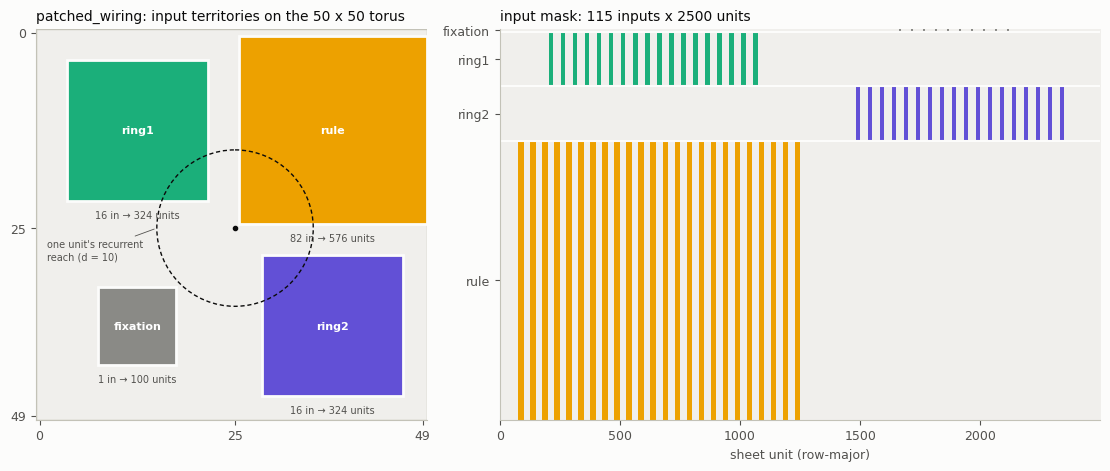

baseline  input weights 287,500   recurrent weights 792,500   (mask: 792,500)
patched_wiring input weights  57,700   recurrent weights 792,500   (mask: 792,500)


In [2]:
fig, (ax_map, ax_mask) = plt.subplots(
    1, 2, figsize=(11, 4.6), width_ratios=[1, 1.5], layout="constrained"
)

ax_map.set_xlim(-0.5, L - 0.5)
ax_map.set_ylim(L - 0.5, -0.5)
ax_map.set_aspect("equal")
ax_map.add_patch(Rectangle((-0.5, -0.5), L, L, facecolor="#f0efec", edgecolor=RULE))
for group, (centre, size) in LAYOUT.items():
    x0, y0 = centre[0] - size / 2, centre[1] - size / 2
    ax_map.add_patch(
        Rectangle((x0, y0), size, size, facecolor=GROUP_COLORS[group], edgecolor=SURFACE, lw=2)
    )
    n_inputs = INPUT_GROUPS[group].stop - INPUT_GROUPS[group].start
    name = group if size >= 10 else "fix"  # the 6x6 fixation patch is too small for the full name
    ax_map.text(
        *centre, name, ha="center", va="center", fontsize=8, color="white", fontweight="bold"
    )
    caption = f"{n_inputs} in → {size * size} units"
    ax_map.text(centre[0], y0 + size + 1.2, caption, ha="center", va="top", fontsize=7, color=MUTED)
ax_map.add_patch(Circle((25, 25), D, facecolor="none", edgecolor=INK, lw=1, ls=(0, (3, 2))))
ax_map.plot(25, 25, marker="o", ms=3, color=INK)
ax_map.annotate(
    "one unit's recurrent\nreach (d = 10)",
    (25 - D, 25),
    (1, 29),
    fontsize=7,
    color=MUTED,
    arrowprops={"arrowstyle": "-", "color": MUTED, "lw": 0.6},
)
ax_map.set_title("patched_wiring: input territories on the 50 x 50 torus", loc="left", fontsize=10)
ax_map.set_xticks([0, 25, 49])
ax_map.set_yticks([0, 25, 49])

mask = input_mask(L, LAYOUT)
group_index = np.zeros(mask.shape, dtype=int)
for i, rows in enumerate(INPUT_GROUPS.values(), start=1):
    group_index[rows] = np.where(mask[rows], i, 0)
cmap = ListedColormap(["#f0efec", *GROUP_COLORS.values()])
ax_mask.imshow(group_index, aspect="auto", cmap=cmap, vmin=0, vmax=4, interpolation="nearest")
ax_mask.set_yticks([(s.start + s.stop - 1) / 2 for s in INPUT_GROUPS.values()], list(INPUT_GROUPS))
for s in list(INPUT_GROUPS.values())[1:]:
    ax_mask.axhline(s.start - 0.5, color=SURFACE, lw=1.5)
ax_mask.set_xlabel("sheet unit (row-major)")
ax_mask.set_title("input mask: 115 inputs x 2500 units", loc="left", fontsize=10)
plt.show()

rec = int(locality_mask(L, D).sum())
for condition in CONDITIONS:
    cfg = runs[condition]["config"]
    n_in, n_rec = cfg["n_input_weights"], cfg["n_recurrent_weights"]
    print(
        f"{condition:9s} input weights {n_in:>7,}   recurrent weights {n_rec:>7,}   (mask: {rec:,})"
    )

## Learning curves

Training loss is a rolling median over 100 steps. Any step with a loss above 5 is marked separately. Accuracy is measured on the fixed evaluation set every 500 steps, both overall and per family:
- **base**: Cog20, 20 tasks
- **int**: interval estimation, 22 tasks
- **seq**: sequence generation, 40 tasks

Khona et al. report about 0.815 overall at 10k steps for this LM-RNN (d = 10), under their (unpublished) metric.

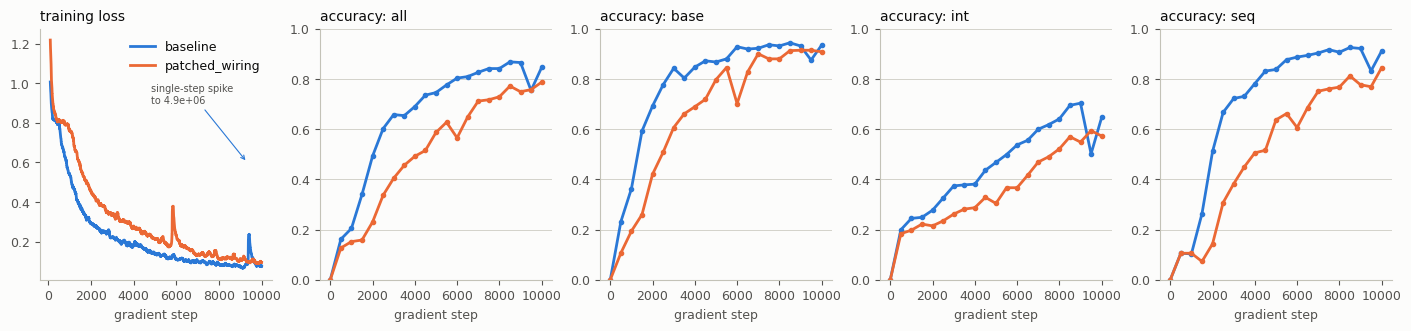

In [3]:
def smooth(steps, values, window=100):
    """Rolling median, so one exploding-gradient step can't swamp the curve."""
    window = min(window, len(values))
    medians = np.median(np.lib.stride_tricks.sliding_window_view(values, window), axis=1)
    return steps[window - 1 :], medians


fig, axes = plt.subplots(1, 5, figsize=(14, 3.2), layout="constrained")
for condition, run in runs.items():
    color = CONDITION_COLORS[condition]
    steps, loss = np.array(run["loss"]).T
    axes[0].plot(*smooth(steps, loss), color=color, lw=2, label=condition)
    for step, value in zip(steps[loss > 5], loss[loss > 5], strict=True):
        axes[0].annotate(
            f"single-step spike\nto {value:.1e}",
            (step, 0.6),
            (step - 4500, 0.9),
            fontsize=7,
            color=MUTED,
            arrowprops={"arrowstyle": "->", "color": color, "lw": 0.8},
        )
    eval_steps = [e["step"] for e in run["evals"]]
    for ax, key in zip(axes[1:], ("all", *FAMILIES), strict=True):
        ax.plot(
            eval_steps,
            [e["summary"][key] for e in run["evals"]],
            color=color,
            lw=2,
            marker="o",
            ms=3,
        )
axes[0].set_title("training loss", loc="left", fontsize=10)
axes[0].legend(frameon=False)
for ax, key in zip(axes[1:], ("all", *FAMILIES), strict=True):
    ax.set_title(f"accuracy: {key}", loc="left", fontsize=10)
    ax.set_ylim(0, 1)
    ax.grid(axis="y", color=RULE, lw=0.5)
for ax in axes:
    ax.set_xlabel("gradient step")
plt.show()

## Final performance per task

Each row is one task, scored on its 32 evaluation trials at the last evaluation. The tasks are grouped by family, and a line joins each task's two conditions. Where only an orange dot shows, the two conditions tie.

The match tasks (`dms`, `dnms`, `dmc`, `dnmc` and their variants) sit near 0.5 even for a network that only fixates. Half of their trials are no-go trials, and fixating is the correct answer on those.

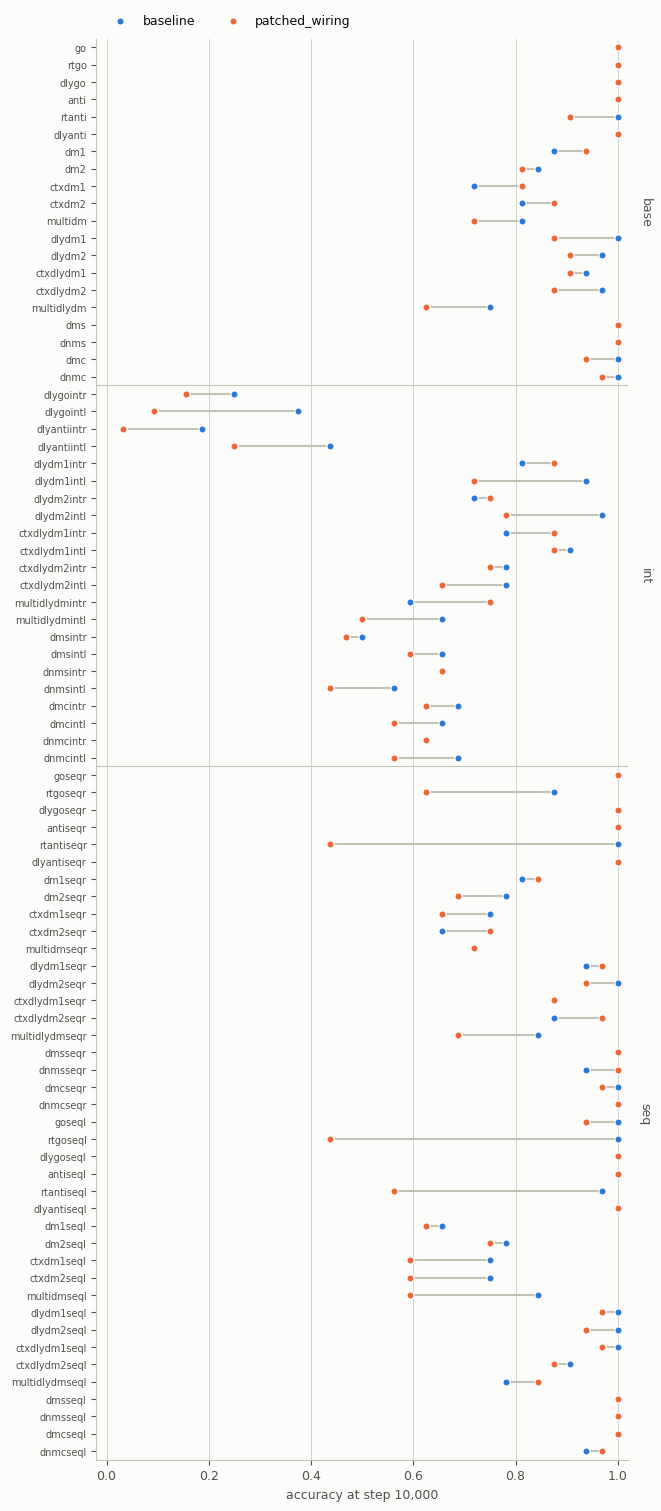

                   all    base     int     seq
baseline         0.846   0.934   0.646   0.911
patched_wiring   0.787   0.908   0.572   0.845
difference      -0.059  -0.027  -0.074  -0.066


In [4]:
final = {c: run["evals"][-1] for c, run in runs.items()}
tasks = list(final["baseline"]["acc"])


def family(task):
    if task.endswith(("seqr", "seql")):
        return "seq"
    return "int" if task.endswith(("intr", "intl")) else "base"


ordered = [t for fam in FAMILIES for t in tasks if family(t) == fam]
y = np.arange(len(ordered))
fig, ax = plt.subplots(figsize=(6.5, 15), layout="constrained")
base_acc = np.array([final["baseline"]["acc"][t] for t in ordered])
patch_acc = np.array([final["patched_wiring"]["acc"][t] for t in ordered])
ax.hlines(y, np.minimum(base_acc, patch_acc), np.maximum(base_acc, patch_acc), color=RULE, lw=1.5)
for condition, acc in (("baseline", base_acc), ("patched_wiring", patch_acc)):
    ax.scatter(
        acc,
        y,
        s=28,
        color=CONDITION_COLORS[condition],
        edgecolor=SURFACE,
        lw=1,
        zorder=3,
        label=condition,
    )
boundary = 0
for fam in FAMILIES:
    n = sum(family(t) == fam for t in ordered)
    ax.text(
        1.02,
        boundary + n / 2 - 0.5,
        fam,
        rotation=-90,
        va="center",
        color=MUTED,
        transform=ax.get_yaxis_transform(),
    )
    boundary += n
    if boundary < len(ordered):
        ax.axhline(boundary - 0.5, color=RULE, lw=0.8)
ax.set_yticks(y, ordered, fontsize=7)
ax.set_ylim(len(ordered) - 0.5, -0.5)
ax.set_xlim(-0.02, 1.02)
ax.set_xlabel(f"accuracy at step {final['baseline']['step']:,}")
ax.grid(axis="x", color=RULE, lw=0.5)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=2, frameon=False)
plt.show()

print(f"{'':14s}" + "".join(f"{k:>8s}" for k in ("all", *FAMILIES)))
for condition in CONDITIONS:
    summary = final[condition]["summary"]
    print(f"{condition:14s}" + "".join(f"{summary[k]:8.3f}" for k in ("all", *FAMILIES)))
gap = {
    k: final["patched_wiring"]["summary"][k] - final["baseline"]["summary"][k]
    for k in ("all", *FAMILIES)
}
print(f"{'difference':14s}" + "".join(f"{gap[k]:+8.3f}" for k in ("all", *FAMILIES)))

## What we see (seed 0)

- **Strict wiring costs about 0.06 overall.** `patched_wiring` reaches 0.79 at 10k steps, against 0.85 for `baseline`. It also trains more slowly: at step 2,000 it scores 0.23 against 0.49, and `baseline` had already passed the patches network's final level by step 6,000. Strict wiring matches or beats dense wiring on 37 of 82 tasks, and wins outright on 14, mostly decision-making (`dm`) tasks and their `int`/`seq` variants.
- **Reaction-time tasks take the largest hit** (mean of the 6 `rt*` tasks: 0.66 against 0.97). Their `seq` variants drop from about 1.0 to 0.44–0.62. In these tasks the response must start on the step the stimulus first appears. Under `patched_wiring` the stimulus reaches only its ring patch, and the rule patch is a recurrent hop away. This is a hypothesis, not a test.
- **Match tasks are close to baseline** (mean of the 20 dms/dnms/dmc/dnmc tasks: 0.82 against 0.85), well clear of the ~0.5 that fixating alone would score.
- **Interval estimation on go/anti (`dlygoint*`, `dlyantiint*`) is hard for both** (0.13 against 0.31).
- **The baseline had one exploding-gradient step.** At step 9,323 its loss hit 4.9 × 10⁶, and it recovered within about 100 steps. Its accuracy fell from 0.868 at step 8,500 to 0.754 at step 9,500, then came back to 0.846. `patched_wiring` had a much smaller bump at step 5,763 (loss 3.3). The setup follows the paper, which mentions no gradient clipping. Comparisons use step 10,000, and the baseline's pre-spike peak would put it about 0.02 higher.

**Compared with the d = 6 pilot** (23% coverage, 0.57; git history): two things changed at once, the radius (6 → 10) and the coverage (23% → 53%). These runs can't say how much each contributed. Layout B (`patches`) at d = 10 would separate them.


## Caveat

There is **one seed per condition**. In Khona et al., the seed-to-seed spread at 10k steps is about ±0.01 (mean ± s.e.m. over 15 seeds), and our strict metric may be noisier per task: 32 trials give a per-task standard error of up to ±0.09. Treat any differences here as preliminary until they replicate across seeds.